# Detection draft: vehicles, speed and type (sections 5-6)

A quick first version, only to see how far we are from the goal.

Plan:
1. **Mask** - the best chain from `search.ipynb` (band-pass 1-100 Hz -> grad -> - median -> threshold -> opening 5x1 -> closing 125x1).
2. **Downsampling** in time 25x (0.04 s per row), so the lines have a visible slope and everything is faster.
3. **Oriented line filter** (lab 2: convolution with own kernel) - a set of short slanted line kernels, one for every speed and direction. A pixel stays only when there is a line with a vehicle-like slope through it. This removes dots and horizontal streaks and fills gaps in dashed lines.
4. **Objects** - connected pixels = one vehicle, its centre line and a straight line fitted to it = speed.
5. **Classification** - by the strength of the original |signal| along the line vs by the width of the line in the mask.
6. **Real data** - two segments: 09:10:52-09:12:52 and 09:12:22-09:14:12.

In [1]:
import glob
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DX = 5.106500953873407   # m between channels
DT = 0.0016              # s between samples
STEP = 25                # downsampling in time: 25 samples -> 1 row
DT2 = DT * STEP          # 0.04 s per row after downsampling


def load_real(first_file, last_file):
    files = sorted(f for f in glob.glob('real-world-data/*.npy') if first_file <= f[-10:-4] <= last_file)
    return np.concatenate([np.load(f) for f in files])


def load_synthetic(i):
    vehicles = json.load(open(f'synthetic-data/{i}_metadata.json'))['ground_truth']['vehicles']
    meta = {v['marker_value']: v for v in vehicles}
    return np.load(f'synthetic-data/{i}_signal.npy'), np.load(f'synthetic-data/{i}_ground_truth.npy'), meta


synthetic = {i: load_synthetic(i) for i in range(40, 46)}
real = {'09:10:52': load_real('091052', '091242'),
        '09:12:22': load_real('091222', '091412')}
print({k: v.shape for k, v in real.items()})

{'09:10:52': (75000, 52), '09:12:22': (75000, 52)}


## 1. Mask from the best chain of `search.ipynb`

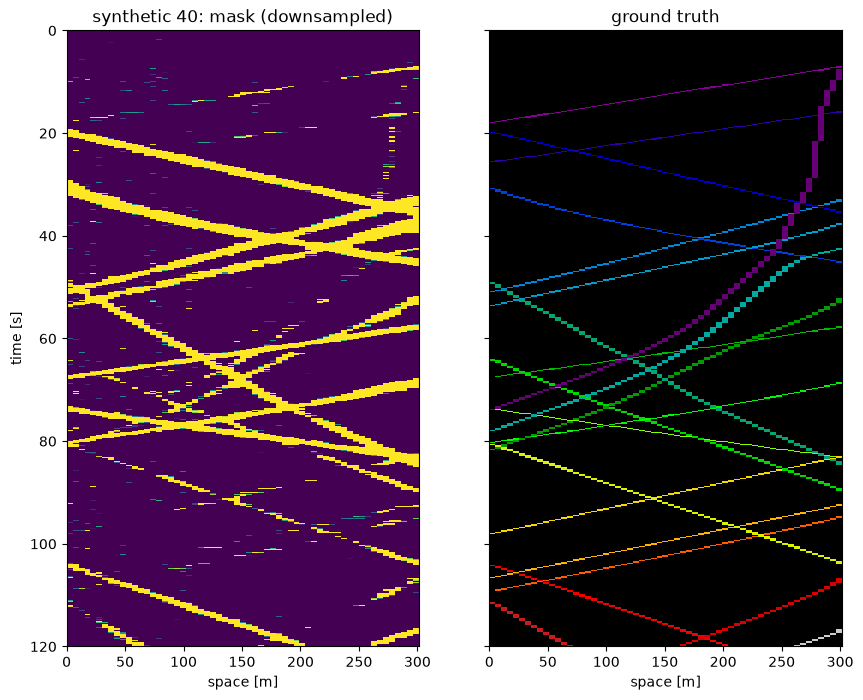

In [2]:
def band_pass(x, low=1, high=100):
    """FFT of every channel along time, keep only low-high Hz."""
    spectrum = np.fft.rfft(x, axis=0)
    freqs = np.fft.rfftfreq(len(x), DT)
    spectrum[(freqs < low) | (freqs > high)] = 0
    return np.fft.irfft(spectrum, n=len(x), axis=0)


def best_mask(x, percentile=75, ratio=None):
    """Best chain from search.ipynb. With `ratio` the threshold is `ratio` x median of the channel instead of a percentile."""
    score = np.abs(np.gradient(band_pass(x), axis=0))
    if ratio is None:
        score = score - np.median(score, axis=0)
        mask = score > np.percentile(score, percentile)
    else:
        mask = score / np.median(score, axis=0) > ratio
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((5, 1), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((125, 1), np.uint8))
    return mask


def downsample(x, how='mean'):
    """Groups of STEP rows -> one row (mean, or max for the ground truth markers)."""
    n = len(x) // STEP * STEP
    blocks = x[:n].reshape(-1, STEP, x.shape[1])
    return blocks.max(axis=1) if how == 'max' else blocks.mean(axis=1)


def show(ax, image, title, **kwargs):
    ax.imshow(image, aspect='auto', interpolation='none', extent=[0, image.shape[1] * DX, len(image) * DT2, 0], **kwargs)
    ax.set_title(title)
    ax.set_xlabel('space [m]')


signal, gt, meta = synthetic[40]
mask_ds = downsample(best_mask(signal).astype(np.float32))
gt_ds = downsample(gt, 'max')

fig, axes = plt.subplots(1, 2, figsize=(10, 8), sharey=True)
show(axes[0], mask_ds, 'synthetic 40: mask (downsampled)')
show(axes[1], gt_ds, 'ground truth', cmap='nipy_spectral')
axes[0].set_ylabel('time [s]')
plt.show()

## 2. Oriented line filter

A vehicle with speed v moves one channel (5.1 m) every `DX / v` seconds, so in the image its line goes down `DX / v / DT2` rows per channel. For every speed 10-130 km/h and both directions we draw such a line, 5 channels long, as a kernel (normalised to sum 1) and convolve the mask with it. The result says what part of that line is covered by the mask. For every pixel we keep the best speed.

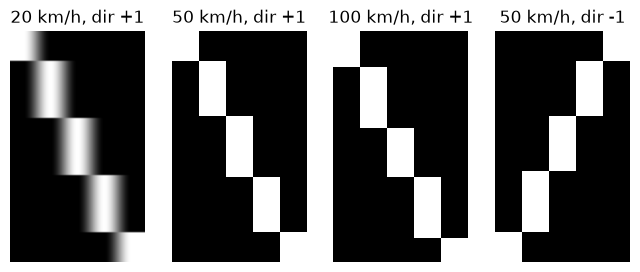

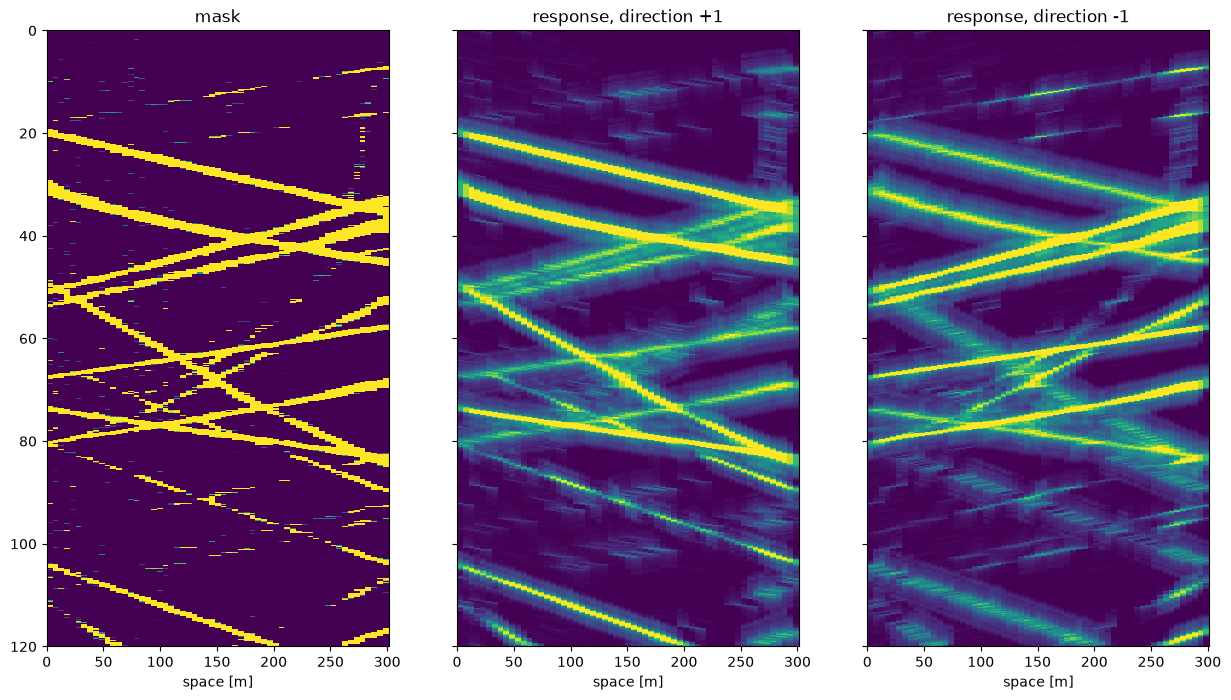

In [3]:
SPEEDS = np.arange(10, 131, 5)   # km/h


def line_kernel(speed_kmh, direction, channels=5):
    rows_per_channel = DX / (speed_kmh / 3.6) / DT2
    kernel = np.zeros((int(round(rows_per_channel * (channels - 1))) + 1, channels), np.float32)
    cols = np.arange(channels) if direction > 0 else np.arange(channels)[::-1]
    for c in range(channels - 1):
        start = (int(cols[c]), int(round(c * rows_per_channel)))
        end = (int(cols[c + 1]), int(round((c + 1) * rows_per_channel)))
        cv2.line(kernel, start, end, 1, 1)
    return kernel / kernel.sum()


def oriented(mask, direction):
    """Best response over all speeds for one direction."""
    responses = np.stack([cv2.filter2D(mask, -1, line_kernel(v, direction), borderType=cv2.BORDER_CONSTANT) for v in SPEEDS])
    return responses.max(axis=0)


fig, axes = plt.subplots(1, 4, figsize=(8, 3))
for ax, (v, d) in zip(axes, [(20, 1), (50, 1), (100, 1), (50, -1)]):
    ax.imshow(line_kernel(v, d), aspect='auto', cmap='gray')
    ax.set_title(f'{v} km/h, dir {d:+d}')
    ax.axis('off')
plt.show()

plus, minus = oriented(mask_ds, 1), oriented(mask_ds, -1)
fig, axes = plt.subplots(1, 3, figsize=(15, 8), sharey=True)
show(axes[0], mask_ds, 'mask')
show(axes[1], plus, 'response, direction +1')
show(axes[2], minus, 'response, direction -1')
plt.show()

## 3. Objects and their speed

For every direction: pixels where the response is above `THRESHOLD` and bigger than the response of the other direction (so crossing vehicles going in opposite directions are split). Connected pixels are one object. Objects shorter than 2 s or 4 channels are removed. The centre line of an object is the mean channel in every row, and a straight line fitted to it (`np.polyfit`) gives the speed.

**Fit check:** if two vehicles touch (e.g. at a crossing), they become one object, the centre line jumps between them and the fitted line goes through empty space. So for every object we compute the **residual** = mean distance (in channels) of the centre points from the fitted line. Objects with residual > `MAX_RESIDUAL` are marked as not straight (dashed orange line, "?").

Tried and rejected: speed taken from the best kernel of the line filter (median over the object's pixels) instead of the fitted line. The mask lines are thick, so a 5-channel kernel fits inside them at several angles and the speed was much worse (median error 10.7 km/h vs 4.3). Longer kernels (10-25 channels) gave a better median (3 km/h) but many huge errors, so the mean was worse than the fitted line.

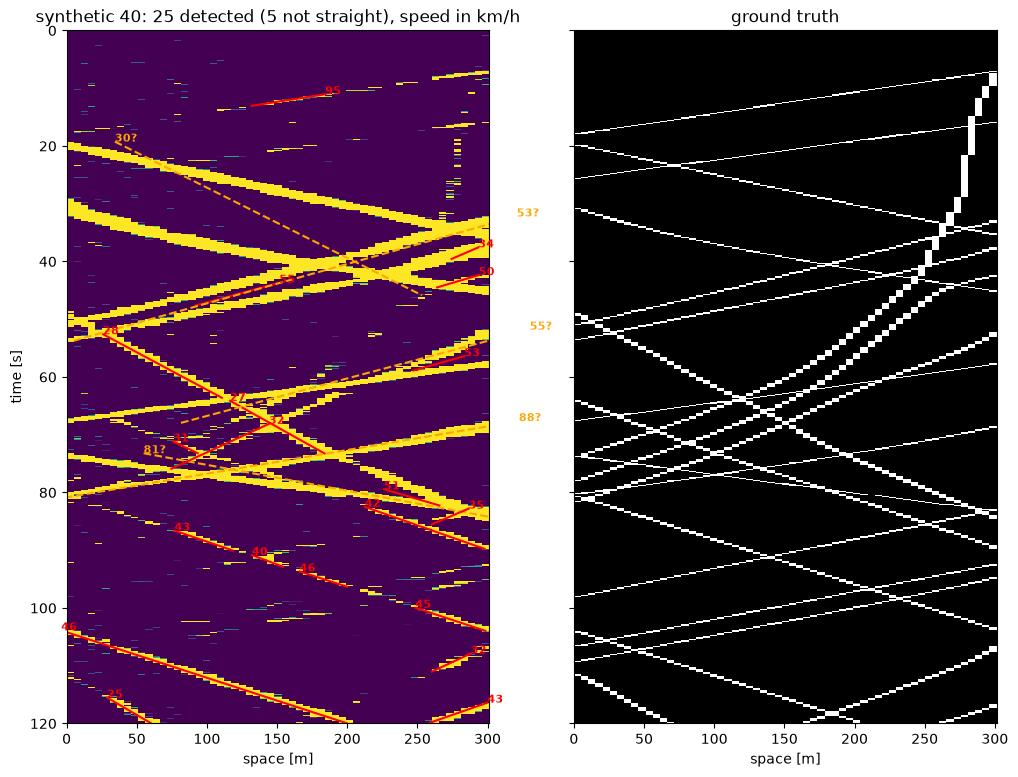

In [4]:
THRESHOLD = 0.5
MAX_RESIDUAL = 1.0   # channels


def detect(mask, threshold=THRESHOLD, min_seconds=2, min_channels=4):
    plus, minus = oriented(mask, 1), oriented(mask, -1)
    vehicles = []
    for direction, response, other in [(1, plus, minus), (-1, minus, plus)]:
        binary = ((response > threshold) & (response >= other)).astype(np.uint8)
        n, labels = cv2.connectedComponents(binary, connectivity=8)
        for label in range(1, n):
            rows, cols = np.nonzero(labels == label)
            if (rows.max() - rows.min()) * DT2 < min_seconds or cols.max() - cols.min() + 1 < min_channels:
                continue
            count = np.bincount(rows - rows.min())
            centre = np.bincount(rows - rows.min(), weights=cols)[count > 0] / count[count > 0]
            centre_rows = np.arange(rows.min(), rows.max() + 1)[count > 0]
            t, x = centre_rows * DT2, centre * DX
            slope, intercept = np.polyfit(t, x, 1)
            residual = np.mean(np.abs(x - (slope * t + intercept))) / DX
            vehicles.append({'direction': direction, 'start [s]': t[0], 'end [s]': t[-1],
                             'speed [km/h]': abs(slope) * 3.6, 'width [channels]': count[count > 0].mean(),
                             'residual [channels]': residual, 'straight': residual <= MAX_RESIDUAL,
                             't': t, 'x': x, 'line': (slope, intercept), 'pixels': (rows, cols),
                             'centre': (centre_rows, np.round(centre).astype(int))})
    return vehicles


def draw(ax, background, vehicles, title, **kwargs):
    show(ax, background, title, **kwargs)
    for v in vehicles:
        t = np.array([v['t'][0], v['t'][-1]])
        x = v['line'][0] * t + v['line'][1]
        color, style, mark = ('red', '-', '') if v['straight'] else ('orange', '--', '?')
        ax.plot(x, t, color=color, linestyle=style, linewidth=1.5)
        ax.text(x[0], t[0], f"{v['speed [km/h]']:.0f}{mark}", color=color, fontsize=8, fontweight='bold')
    ax.set_xlim(0, background.shape[1] * DX)
    ax.set_ylim(len(background) * DT2, 0)


vehicles = detect(mask_ds)
n_bad = sum(not v['straight'] for v in vehicles)
fig, axes = plt.subplots(1, 2, figsize=(12, 9), sharey=True)
draw(axes[0], mask_ds, vehicles, f'synthetic 40: {len(vehicles)} detected ({n_bad} not straight), speed in km/h')
draw(axes[1], gt_ds > 0, [], 'ground truth', cmap='gray')
axes[0].set_ylabel('time [s]')
plt.show()

## 4. Check on all synthetic examples

Every detected object gets the ground truth vehicle that has the most pixels inside it. The reference speed is a line fitted to the ground truth pixels of that vehicle **in the same time window as the object** (the metadata has no speed, and vehicles change speed, so a fragment should be compared with the speed at that moment, not the average over the whole vehicle).
- **found** - vehicles that got at least one object,
- **fragments** - extra objects of an already found vehicle (one vehicle cut into pieces),
- **empty** - objects without any ground truth vehicle (false detections).

In [5]:
def reference_speed(gt_ds, marker, first_row=0, last_row=None):
    rows, cols = np.nonzero(gt_ds[first_row:last_row] == marker)
    if len(rows) > 5 and cols.max() - cols.min() >= 2:
        return abs(np.polyfit(rows * DT2, cols * DX, 1)[0]) * 3.6
    return np.nan


def signal_ratio(x):
    """Original |signal| (downsampled) divided by the median of its channel - how much stronger than the background."""
    a = downsample(np.abs(x))
    return a / np.median(a, axis=0)


summary, detections = [], []
for i, (signal, gt, meta) in synthetic.items():
    mask = downsample(best_mask(signal).astype(np.float32))
    gt_ds = downsample(gt, 'max')
    ratio = signal_ratio(signal)
    speeds = {m: reference_speed(gt_ds, m) for m in meta}
    speeds = {m: s for m, s in speeds.items() if not np.isnan(s)}   # vehicles visible enough to count
    found, empty = set(), 0
    for v in detect(mask):
        markers = gt_ds[v['pixels']]
        markers = markers[markers > 0]
        v['strength'] = np.median(ratio[v['centre']])
        if len(markers) == 0:
            empty += 1
            continue
        marker = np.bincount(markers).argmax()
        found.add(marker)
        detections.append({'sample': i, 'type': meta[marker]['type'], 'true direction': meta[marker]['direction'],
                           'true speed [km/h]': reference_speed(gt_ds, marker, v['pixels'][0].min(), v['pixels'][0].max() + 1),
                           'duration [s]': v['end [s]'] - v['start [s]'],
                           **{k: v[k] for k in ['direction', 'speed [km/h]', 'width [channels]', 'strength',
                                                'residual [channels]', 'straight']}})
    types = pd.Series({m: meta[m]['type'] for m in speeds})
    n_objects = sum(d['sample'] == i for d in detections)
    summary.append({'sample': i, 'vehicles': len(types), 'found': len(found & set(types.index)),
                    'cars found': f"{sum(types[m] == 'car' for m in found if m in types)}/{(types == 'car').sum()}",
                    'trams found': f"{sum(types[m] == 'tram' for m in found if m in types)}/{(types == 'tram').sum()}",
                    'fragments': n_objects - len(found), 'empty': empty})

summary = pd.DataFrame(summary).set_index('sample')
detections = pd.DataFrame(detections)
display(summary)
print(f"found {summary['found'].sum()} of {summary['vehicles'].sum()} vehicles "
      f"({summary['found'].sum() / summary['vehicles'].sum():.0%}), "
      f"{summary['fragments'].sum()} fragments, {summary['empty'].sum()} empty objects")

,vehicles,found,cars found,trams found,fragments,empty
sample,,,,,,
40,22,16,10/14,5/7,7,2
41,18,13,7/10,3/5,7,1
42,20,16,9/12,7/8,8,0
43,24,15,8/14,4/7,11,0
44,30,21,12/18,9/12,14,1
45,20,15,6/11,8/8,6,0


found 96 of 134 vehicles (72%), 53 fragments, 4 empty objects


direction correct: 93%


,objects,median error,mean error,90% below
all objects,149.0,3.3,8.7,23.1
straight (residual <= 1.0),118.0,2.5,6.5,14.7
not straight,31.0,8.1,17.0,45.1
straight and longer than 3 s,75.0,2.0,3.7,5.3


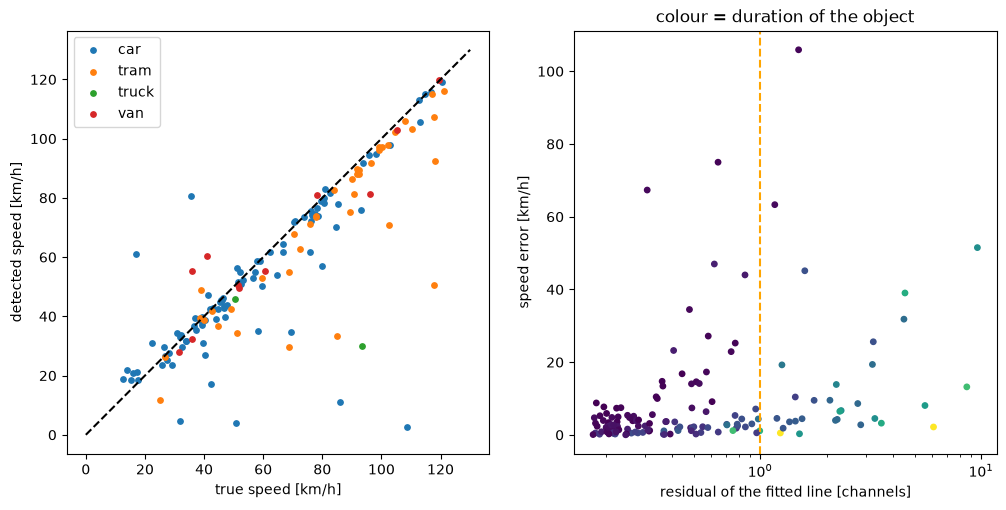

In [6]:
detections['speed error [km/h]'] = (detections['speed [km/h]'] - detections['true speed [km/h]']).abs()
print(f"direction correct: {(detections['direction'] == detections['true direction']).mean():.0%}")
groups = {'all objects': detections,
          f'straight (residual <= {MAX_RESIDUAL})': detections[detections['straight']],
          'not straight': detections[~detections['straight']],
          'straight and longer than 3 s': detections[detections['straight'] & (detections['duration [s]'] > 3)]}
display(pd.DataFrame({name: {'objects': len(part),
                             'median error': part['speed error [km/h]'].median(),
                             'mean error': part['speed error [km/h]'].mean(),
                             '90% below': part['speed error [km/h]'].quantile(0.9)}
                      for name, part in groups.items()}).T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for t, part in detections.groupby('type'):
    axes[0].scatter(part['true speed [km/h]'], part['speed [km/h]'], label=t, s=15)
axes[0].plot([0, 130], [0, 130], 'k--')
axes[0].set_xlabel('true speed [km/h]')
axes[0].set_ylabel('detected speed [km/h]')
axes[0].legend()
axes[1].scatter(detections['residual [channels]'], detections['speed error [km/h]'], s=15,
                c=detections['duration [s]'], cmap='viridis')
axes[1].axvline(MAX_RESIDUAL, color='orange', linestyle='--')
axes[1].set_xscale('log')
axes[1].set_xlabel('residual of the fitted line [channels]')
axes[1].set_ylabel('speed error [km/h]')
axes[1].set_title('colour = duration of the object')
plt.show()

## 5. Classification

Two features for every object:
- **width** - mean width of the object in the mask (channels). Opening/closing and the line filter make lines wider, so this may be biased.
- **strength** - median of the original |signal| / channel median along the centre line (as in table 4 of the report: car 2.1x, van 3.0x, truck 4.4x, tram 9.6x).

Thresholds between classes: geometric mean of the medians of two neighbouring classes. Chosen on the same 6 examples, so the accuracy is optimistic.

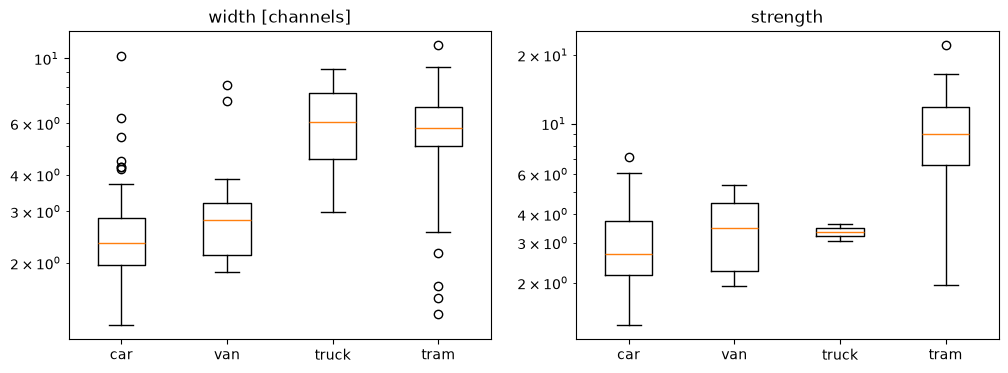

type
car      95
tram     40
van      12
truck     2
Name: count, dtype: int64
width [channels]  ['car', 'van', 'truck', 'tram']: accuracy 54%, thresholds [2.56 4.12 5.92]


predicted,car,tram,truck,van
true,,,,
car,56,2,5,32
tram,5,19,16,0
truck,0,1,0,1
van,5,2,0,5


strength          ['car', 'van', 'truck', 'tram']: accuracy 61%, thresholds [3.04 3.4  5.47]


predicted,car,tram,truck,van
true,,,,
car,58,3,30,4
tram,4,32,4,0
truck,0,0,1,1
van,5,0,7,0


width [channels]  ['car', 'tram']: accuracy 90%, thresholds [3.67]


predicted,car,tram
true,,
car,87,8
tram,5,35


strength          ['car', 'tram']: accuracy 90%, thresholds [4.89]


predicted,car,tram
true,,
car,86,9
tram,5,35


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = ['car', 'van', 'truck', 'tram']
for ax, feature in zip(axes, ['width [channels]', 'strength']):
    ax.boxplot([detections.loc[detections['type'] == t, feature] for t in order], tick_labels=order)
    ax.set_title(feature)
    ax.set_yscale('log')
plt.show()
print(detections['type'].value_counts())


def fit_thresholds(values, labels, classes):
    medians = [values[labels == c].median() for c in classes]
    return [np.sqrt(a * b) for a, b in zip(medians[:-1], medians[1:])]


def classify(values, thresholds, classes):
    return np.array(classes)[np.searchsorted(thresholds, values)]


for classes in [['car', 'van', 'truck', 'tram'], ['car', 'tram']]:
    part = detections[detections['type'].isin(classes)]
    for feature in ['width [channels]', 'strength']:
        thresholds = fit_thresholds(part[feature], part['type'], classes)
        predicted = classify(part[feature], thresholds, classes)
        print(f"{feature:17s} {classes}: accuracy {(predicted == part['type']).mean():.0%}, thresholds {np.round(thresholds, 2)}")
        display(pd.crosstab(part['type'], predicted, rownames=['true'], colnames=['predicted']))

## 6. Speed over time

The centre line of an object, smoothed with a 2 s moving average; its derivative is the speed at every moment. Example: in synthetic 40, the 3 detected objects (longer than 10 s) whose speed changes the most, compared with the same calculation on their ground truth vehicle.

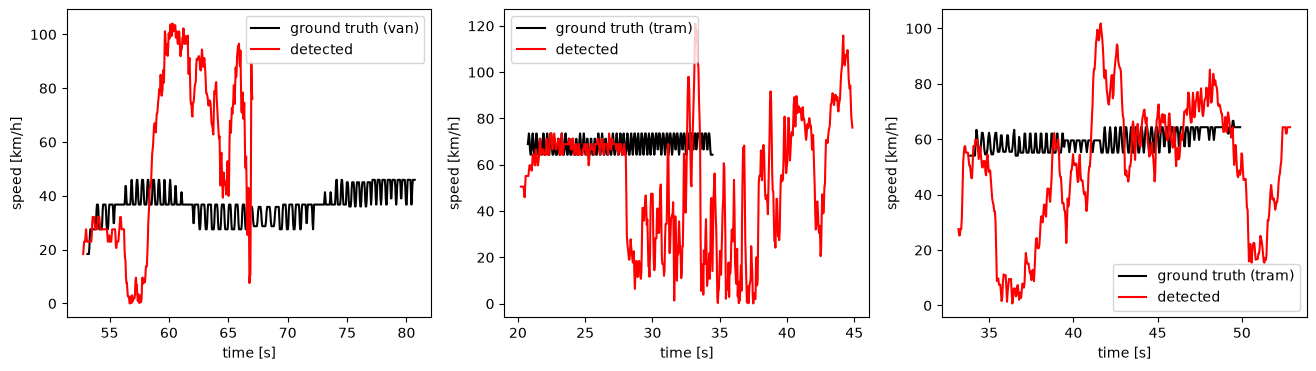

In [8]:
def speed_over_time(t, x, window_s=2.0):
    w = max(int(window_s / DT2), 1)
    x_smooth = np.convolve(x, np.ones(w) / w, mode='valid')
    t_smooth = np.convolve(t, np.ones(w) / w, mode='valid')
    return t_smooth, np.abs(np.gradient(x_smooth, t_smooth)) * 3.6


def centre_line(rows, cols):
    count = np.bincount(rows - rows.min())
    centre = np.bincount(rows - rows.min(), weights=cols)[count > 0] / count[count > 0]
    return np.arange(rows.min(), rows.max() + 1)[count > 0] * DT2, centre * DX


signal, gt, meta = synthetic[40]
gt_ds = downsample(gt, 'max')
long_ones = [v for v in detect(downsample(best_mask(signal).astype(np.float32))) if v['t'][-1] - v['t'][0] > 10]
for v in long_ones:
    _, speed = speed_over_time(v['t'], v['x'])
    v['speed change'] = np.percentile(speed, 90) - np.percentile(speed, 10)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, v in zip(axes, sorted(long_ones, key=lambda v: -v['speed change'])):
    markers = gt_ds[v['pixels']]
    marker = np.bincount(markers[markers > 0]).argmax()
    ax.plot(*speed_over_time(*centre_line(*np.nonzero(gt_ds == marker))), 'k', label=f"ground truth ({meta[marker]['type']})")
    ax.plot(*speed_over_time(v['t'], v['x']), 'r', label='detected')
    ax.set_xlabel('time [s]')
    ax.set_ylabel('speed [km/h]')
    ax.legend()
plt.show()

## 7. Real data

The 75th percentile from `search.ipynb` marks 25% of the pixels as vehicles. Synthetic data has vehicles all the time, real data has quiet periods, so on real data this floods the picture. Below the same chain with a threshold that does not depend on the amount of traffic: **4 x the median of the channel** (chosen by eye, real data has no ground truth).

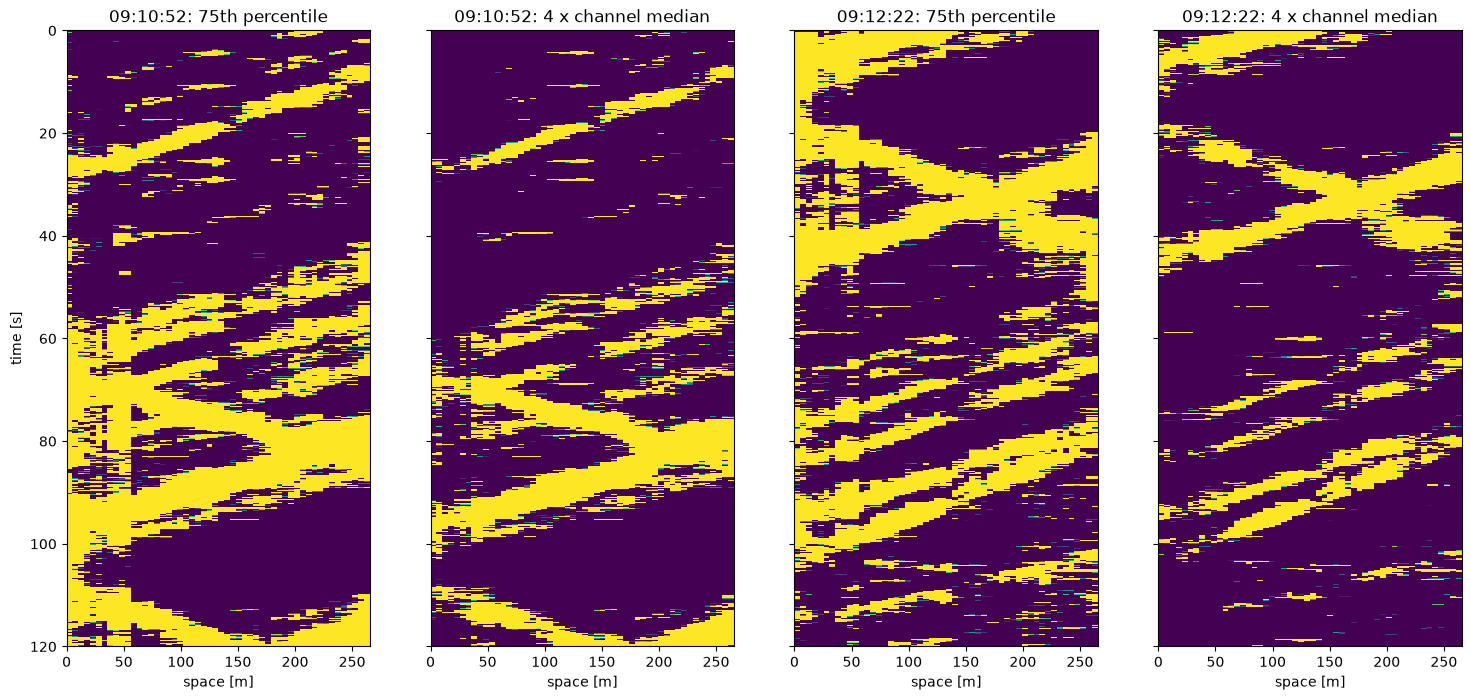

In [9]:
REAL_RATIO = 4

fig, axes = plt.subplots(1, 4, figsize=(18, 8), sharey=True)
for k, (name, x) in enumerate(real.items()):
    show(axes[2 * k], downsample(best_mask(x).astype(np.float32)), f'{name}: 75th percentile')
    show(axes[2 * k + 1], downsample(best_mask(x, ratio=REAL_RATIO).astype(np.float32)), f'{name}: {REAL_RATIO} x channel median')
axes[0].set_ylabel('time [s]')
plt.show()

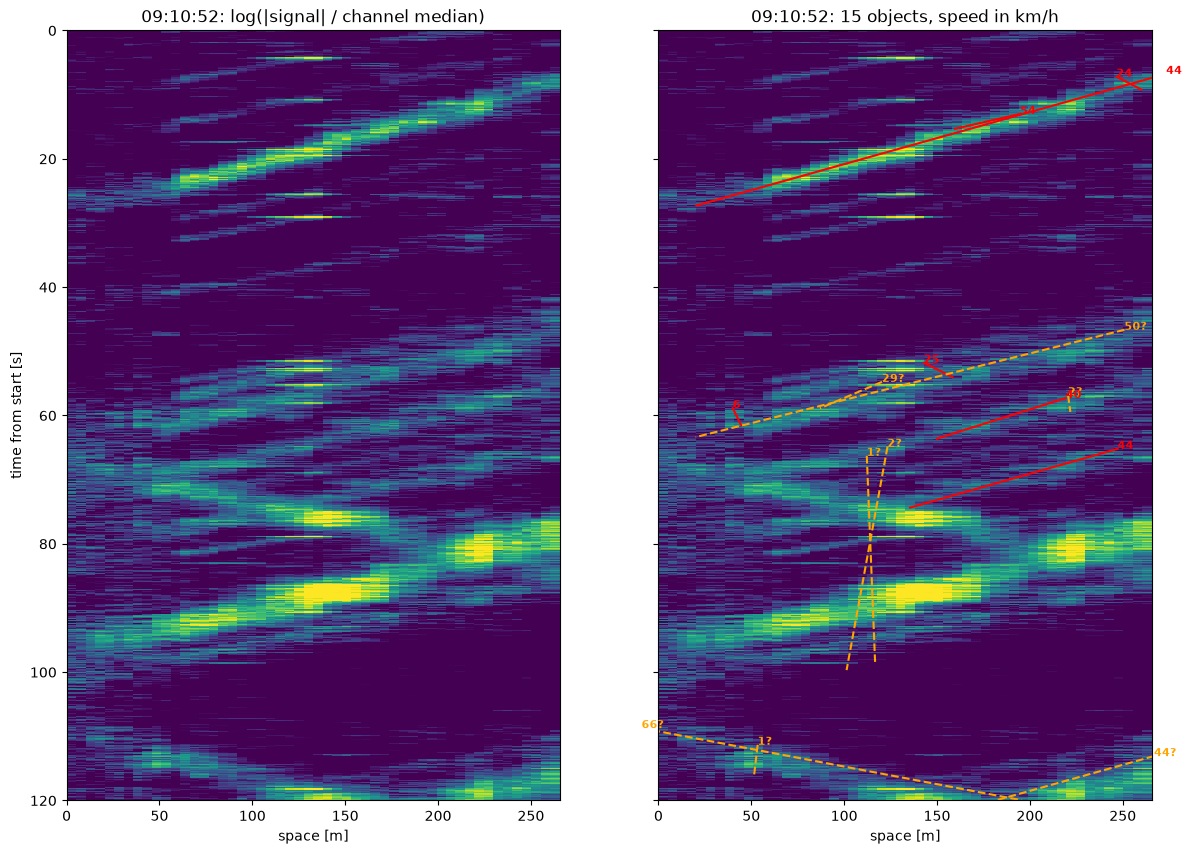

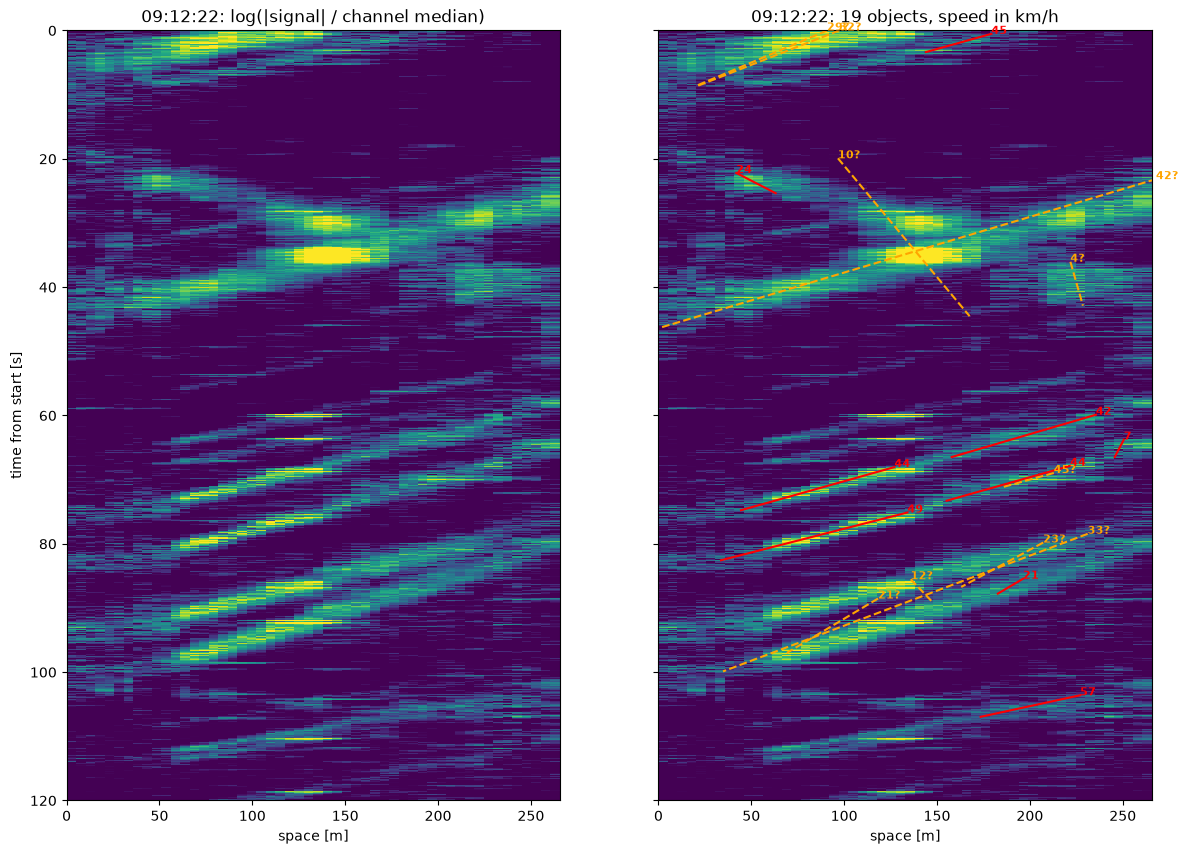

In [10]:
real_vehicles = {}
for name, x in real.items():
    mask = downsample(best_mask(x, ratio=REAL_RATIO).astype(np.float32))
    ratio = signal_ratio(x)
    real_vehicles[name] = detect(mask)
    for v in real_vehicles[name]:
        v['strength'] = np.median(ratio[v['centre']])
    background = np.log(ratio)
    fig, axes = plt.subplots(1, 2, figsize=(14, 10), sharey=True)
    draw(axes[0], background, [], f'{name}: log(|signal| / channel median)', vmin=0, vmax=np.percentile(background, 99.5))
    draw(axes[1], background, real_vehicles[name], f'{name}: {len(real_vehicles[name])} objects, speed in km/h',
         vmin=0, vmax=np.percentile(background, 99.5))
    axes[0].set_ylabel('time from start [s]')
    plt.show()

In [11]:
strength_thresholds = fit_thresholds(detections['strength'], detections['type'], ['car', 'tram'])
tables = []
for name, vehicles in real_vehicles.items():
    table = pd.DataFrame([{k: v[k] for k in ['direction', 'start [s]', 'end [s]', 'speed [km/h]', 'straight', 'width [channels]', 'strength']}
                          for v in vehicles])
    table['class (synthetic thresholds)'] = classify(table['strength'], strength_thresholds, ['car', 'tram'])
    table.insert(0, 'segment', name)
    tables.append(table)
real_table = pd.concat(tables, ignore_index=True)
display(real_table.round(1))
print(real_table.groupby('segment')['strength'].describe().round(1))

,segment,direction,start [s],end [s],speed [km/h],straight,width [channels],strength,class (synthetic thresholds)
0,09:10:52,1,7.2,9.2,24.1,True,1.4,4.6,car
1,09:10:52,1,13.0,15.3,54.5,True,3.7,7.1,tram
2,09:10:52,1,51.8,54.0,25.1,True,6.2,3.3,car
3,09:10:52,1,54.8,58.9,29.2,False,5.2,2.9,car
4,09:10:52,1,56.8,59.4,1.7,False,4.9,3.3,car
5,09:10:52,1,58.8,61.5,6.1,True,3.1,3.0,car
6,09:10:52,1,66.3,98.4,0.5,False,14.8,7.1,tram
7,09:10:52,1,108.7,120.0,65.5,False,13.3,2.1,car
8,09:10:52,-1,6.8,27.3,44.4,True,5.7,7.5,tram
9,09:10:52,-1,46.6,63.4,49.7,False,7.3,3.3,car


          count  mean  std  min  25%  50%  75%  max
segment                                            
09:10:52   15.0   4.1  1.9  2.1  3.0  3.3  5.4  7.5
09:12:22   19.0   4.0  1.7  1.7  2.6  3.7  4.8  7.4


## Summary of the draft - how far are we

**Works:**
- Synthetic: 72% of vehicles found (cars 52/79 = 66%, trams 36/47 = 77%), almost no false objects (4 empty objects in 6 examples).
- Direction correct for 93% of objects. Speed error (vs ground truth in the same time window): median 3.3 km/h for all objects, 2.5 km/h for straight ones (residual <= 1 channel), and **2.0 km/h median / 3.7 mean / 90% below 5.3 km/h for straight objects longer than 3 s**. The remaining big errors are short (2-3 s) fragments.
- The fit check (residual) marks the wrong lines at crossings (e.g. the "30" line in synthetic 40) and the ~0-2 km/h blobs on real data. On real data it also marks some lines that look fine - lines are wider and noisier there, so 1 channel may be too strict.
- Classification car vs tram: 90% with both features (width from the mask and |signal| strength) - but thresholds chosen on the same data.
- Real data: separate vehicles on clear parts are found with plausible city speeds (about 20-65 km/h).

**Does not work yet:**
- **Crossings and dense traffic**: crossing vehicles merge into one object -> one wrong line (e.g. "10 km/h" across an X), and centre line jumping between vehicles (speed over time goes crazy exactly there).
- **Fragments**: one vehicle is often cut into 2-3 objects (53 fragments on synthetic) -> too many vehicles counted. Needs joining pieces that lie on the same line.
- **Big blobs on real data**: two heavy vehicles close to each other (09:10:52, 65-100 s) give a huge object with speed ~0-2 km/h.
- **The 75th percentile does not work on real data** (floods the picture) - here replaced with 4 x channel median, chosen by eye.
- **4 classes**: car / van / truck / tram only 54-61% - van and truck are almost not separable (12 vans, 2 trucks detected in total).
- Strength on real data is about 2-7.5 x, synthetic thresholds (car/tram at 4.9 x) may not fit real data.

**Next steps:**
1. Split objects at crossings (e.g. one object per kernel speed group, or skeleton + cutting at branch points).
2. Join fragments lying on the same line (same direction, similar speed, extrapolated line hits the next piece).
3. Remove objects with speed below the slowest kernel (they are blobs, not vehicles).
4. Choose the real-data threshold in a better way than by eye.
5. Leave-one-out for classification thresholds; maybe 3 classes: car / heavy / tram.